# Evaluation of Source Reconstruction Methods

In this tutorial, we will explore how to evaluate source reconstruction methods when a ground truth is available. Typically, the ground truth is obtained from simulations. Keep in mind that the accuracy of any reconstruction method is inherently limited by the quality and assumptions of the simulation used to generate the ground truth. <br>

To assess the performance of the reconstruction, we will use a set of evaluation metrics, which will be described in detail in the following sections. <br>

1. Apply source reconstruction methods
2. Measure metrics comparing reconstruction and ground truth
3. Plot metrics in different ways

**Requirements**:
- Generate simulated dataset

## 📦 Imports

In [1]:
import mindmap as mm

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `src`: Source space (after forward solution)
- `sc`: Connectome
- `parc`: Parcellation
- `cras`: Translation (T1 -> RAS)

🎚️ **<font color=pink>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: subject id

In [5]:
######### Parameters ###########
fconfig = "../../papers/simf/configuration.yml"
sub     = 1
samp    = 10
################################

reader = mm.io.dataset_reader(fconfig)
data   = reader(sub, "src", "gt", "eeg", "cst", "fwd", sample=samp)

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- eeg
- fwd
- cst
- gt
- src
Missing objects:


## 1. Apply source reconstruction method

In [ ]:
############## Parameters ##################
cset_lam    = 0.01
sloreta_lam = 0.01
wcset_lam   = 0.01
############################################

cset    = mm.cset(data["eeg"], data["fwd"], data["cst"], lam=cset_lam)
sloreta = mm.sloreta(data["eeg"], data["fwd"], lam=sloreta_lam)
#wcset   = mm.wcset(data["eeg"], data["fwd"], data["cst"], weights, lam=wcset_lam)

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.


## 2. Evaluate methods

In [12]:
cset_eval = mm.utils.binary_classification(data["gt"], cset, 0.8)
sloreta_eval = mm.utils.binary_classification(data["gt"], sloreta, 0.8)

## 3. Plot metrics

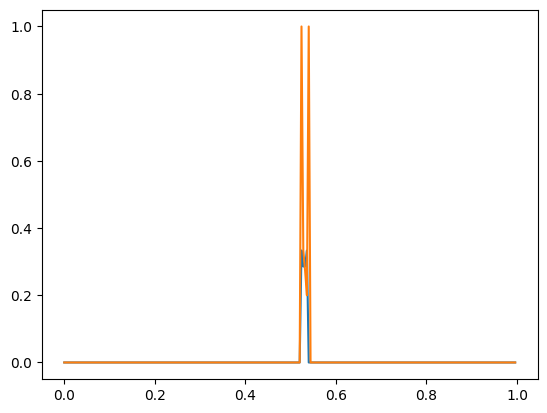

In [15]:
import matplotlib.pyplot as plt

plt.plot(cset.times, cset_eval["precision"])
plt.plot(sloreta.times, sloreta_eval["precision"])

plt.show()

In [44]:
def activity_mask(signal, q=0.95):
    """
    Generate mask of activity.

    Parameters:
    ----------
    signal: (N,) as float
        Brain signal.
    q: float [0-1]
        Quantile above which signal is active.

    Returns:
    ------- 
    activity: (N,) as bool
        Brain activity
    """
    if q < 0 or q > 1:
        raise ValueError("q must be between 0 and 1")
    
    thr = np.quantile(signal, q=q)
    activity = signal > thr
    
    return activity


activity1 = activity_mask(signal1, q=0.90)
mm.viz.plot_brain_signal(data["src"], activity1, cmap="reds").show()
print(f"Active sources: {activity1.sum()}, None active sources: {len(activity1)-activity1.sum()}")

Widget(value='<iframe src="http://localhost:36695/index.html?ui=P_0x7f9c9ab79a60_24&reconnect=auto" class="pyv…

Active sources: 496, None active sources: 4461


In [26]:
def perform_roc(prediction, reference, samples=100):
    """
    Measure performance of binary classifier model at varying threshold values (receiver operating characteristic curve - roc)

    Parameters:
    ----------
    prediction: (N,)
        Prediction signal.

    reference: (N,)
        Reference signal of the same length as 'prediction' 

    samples: int
        Number of classifiers to test.

    Returns:
    -------
    results: pd.DataFrame
        Table containing all measurements
        - classifier: int [0-1]
            classifier threshold
        - TP: int
            True positives
        - TN: int
            True negatives
        - FP: int
            False positives 
        - FN: int 
            False negatives.
        - sensitivity: float
            TP / (TP+FN)
        - specificity: float
            TN / (TN+FP)
        - accuracy: float
            TP + TN / (TP + TN + FP + FN)
        - precision: float
            TP / (TP + FP)
    """

    # Compute normalized energy
    Epred = prediction**2 / np.max(prediction**2)
    Eref  = reference**2 / np.max(reference**2)

    # classifiers
    classifiers = np.linspace(0,1,samples)

    # generate metrics
    results = {"classifier":[], "TP":[], "TN":[], "FP":[], "FN":[]}
    for c in classifiers:
        counts = 2*(Epred > c) + (Eref > c)

        results["classifier"].append(c) 
        results["TN"].append(np.sum(counts==0))
        results["FN"].append(np.sum(counts==1))
        results["FP"].append(np.sum(counts==2))
        results["TP"].append(np.sum(counts==3))


    results = pd.DataFrame(results)

    results["sens"] = results["TP"] / (results["TP"]+results["FN"])
    results["spec"] = results["TN"] / (results["TN"]+results["FP"])
    results["acc"]  = (results["TP"] + results["TN"]) / (results["TP"]+results["TN"]+results["FP"]+results["FN"])
    results["prec"] = results["TP"] / (results["TP"]+results["FP"])

    return results

In [ ]:
signal1 = np.random.rand(10000)
signal2 = np.random.rand(10000)

results = perform_roc(signal1, signal2)

<Axes: xlabel='classifier', ylabel='acc'>

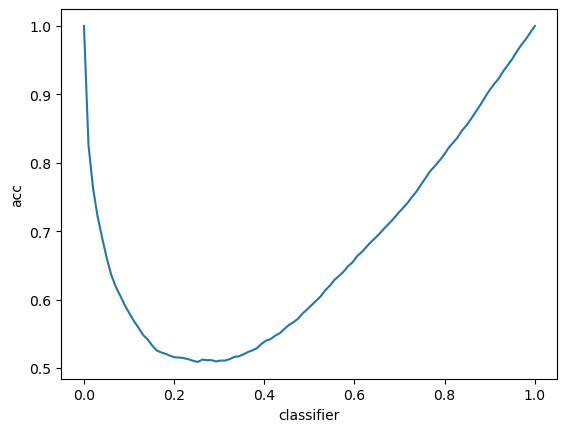

In [28]:
sns.lineplot(data=results, x=results["classifier"], y=results["acc"])

In [29]:
def plot_roc(results, x="spec", y="sens"):
    """
    Plot a receiver operating characteristic curve (roc)
    """
    r = results.copy()
    r[x] = 1-r[x]

    sns.lineplot(data=r, x=x, y=y, errorbar=None)
    plt.plot([0,1], [0,1])

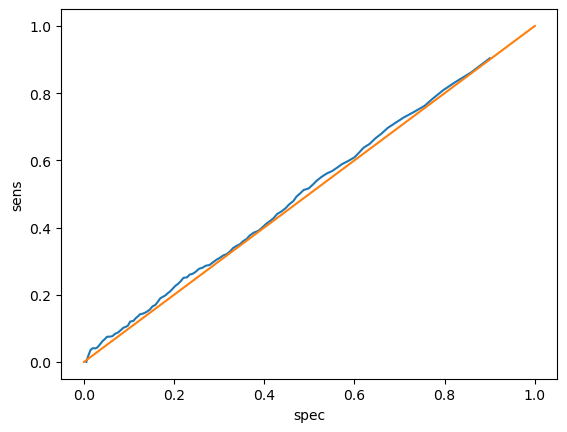

In [30]:
plot_roc(results)